<a href="https://colab.research.google.com/github/jayeshkoli-1402/ML-LAB/blob/main/ML_Lab_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Student Name:** Jayesh Ravindra Koli

**Div:** CSE-A

**Practical Batch:** A2

**Roll No:** 56

**Date:** 22/09/2026

**Practical NO:** 03

**Practical Name:** Decision Tree

# **3] Implementation of a toy classification problem using decision boundaries. Apply train-test-split and k-fold cross-validation to a dataset (e.g., Iris). Compare accuracy, precision, recall, F1-score.**

# **1. Import Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

In [2]:
iris = load_iris()
data = pd.DataFrame(iris.data, columns=iris.feature_names)

data["Species"] = iris.target
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
data["Species"].head()

,Species
0,0
1,0
2,0
3,0
4,0


# **2. Data Collection And EDA**

In [4]:
data.shape

(150, 5)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [6]:
data["Species"].value_counts()

,count
Species,
0,50
1,50
2,50


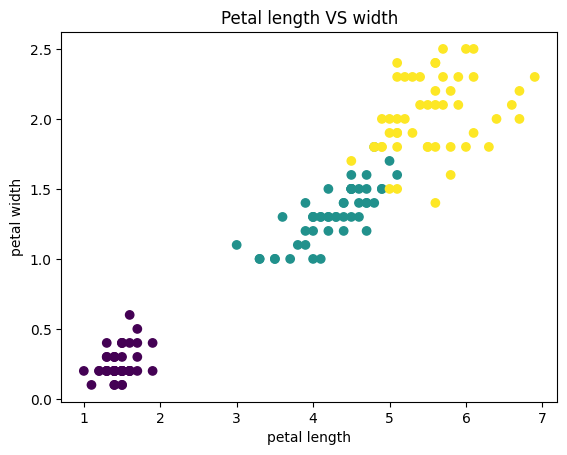

In [7]:
plt.scatter(data['petal length (cm)'], data['petal width (cm)'], c=data["Species"])

plt.xlabel("petal length")
plt.ylabel("petal width")

plt.title("Petal length VS width")
plt.show()

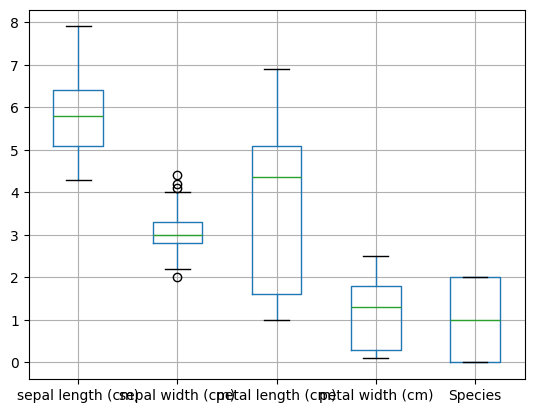

In [8]:
data.boxplot()
plt.show()

In [9]:
X = data.iloc[:, :4]
Y = data.iloc[:, -1]

In [10]:
Y.head()

,Species
0,0
1,0
2,0
3,0
4,0


In [11]:
from sklearn.model_selection import train_test_split

In [12]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2,)
X_train.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
8,4.4,2.9,1.4,0.2
81,5.5,2.4,3.7,1.0
66,5.6,3.0,4.5,1.5
10,5.4,3.7,1.5,0.2
125,7.2,3.2,6.0,1.8


# **3. Model Building**

In [13]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_depth=3, random_state =1, )
model.fit(X_train, Y_train)

DecisionTreeClassifier(max_depth=3, random_state=1)

In [14]:
y_pred = model.predict(X_test)
y_pred[:10]

array([1, 2, 0, 2, 1, 0, 1, 1, 1, 2])

In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Train Test Split Results: ")

print(f"Accuracy: {accuracy_score(Y_test, y_pred)}")
print(f"Precision: {precision_score(Y_test, y_pred, average='weighted')}")
print(f"Recall: {recall_score(Y_test, y_pred,average='weighted')}")
print(f"F1 Score: {f1_score(Y_test, y_pred,average='weighted')}")

Train Test Split Results: 
Accuracy: 0.9666666666666667
Precision: 0.9696969696969696
Recall: 0.9666666666666667
F1 Score: 0.9667356797791581


# **4. K-Fold Cross Validation**

In [16]:
from sklearn.model_selection import KFold, cross_validate


kf = KFold(n_splits=5, shuffle=True, random_state =1)
results = cross_validate(model, X, Y, cv=kf,
                         scoring= ["accuracy", "precision_weighted", "recall_weighted", "f1_weighted"])


In [17]:
print("\n5-Fold Cross Validation Results: ")
print(f"Accuracy: {np.mean(results['test_accuracy'])}")
print(f"Precision: {np.mean(results['test_precision_weighted'])}")
print(f"Recall: {np.mean(results['test_recall_weighted'])}")
print(f"F1 Score: {np.mean(results['test_f1_weighted'])}")


5-Fold Cross Validation Results: 
Accuracy: 0.9199999999999999
Precision: 0.9253040293040293
Recall: 0.9199999999999999
F1 Score: 0.9184025234025235
